# 01, Genome-wide causal search across the coding genome

**Place in the argument.** Track 1, discovery. It tests whether the `BUB1B` hypothesis survives
when it competes against every gene, not against a panel chosen by hand.

**Main output.** A genome-wide ranking, its stability under perturbation, and a methodological
comparison with Exomiser. It does not classify variants and does not demonstrate causality.

> **This notebook re-runs the experiment from its inputs.** It does not display stored results:
> it imports `src/`, which is the source of truth.
>
> **Sanitised output.** Aggregates, counts and gene symbols only; never coordinates, genotypes or
> variant identities. The notebook runs the sanitisation scanner at the end.

## The biological question

**Which gene best explains the case when the whole coding genome competes?**

Until EXP-006, `BUB1B` looked strong **inside a panel we had chosen**. That is not the same as
surviving a search without a panel.

## Hypothesis and preregistration

`docs/DECISIONS.md` § EXP-006, written before execution. The deciding prediction is #4:
**`BUB1B` ranks in the top 20** without a panel. Both outcomes were declared useful in advance:
had it not ranked high, we would have avoided an error.

**Design guarantee:** `src/prioritization/extract_genomewide.py` does not mention any gene.

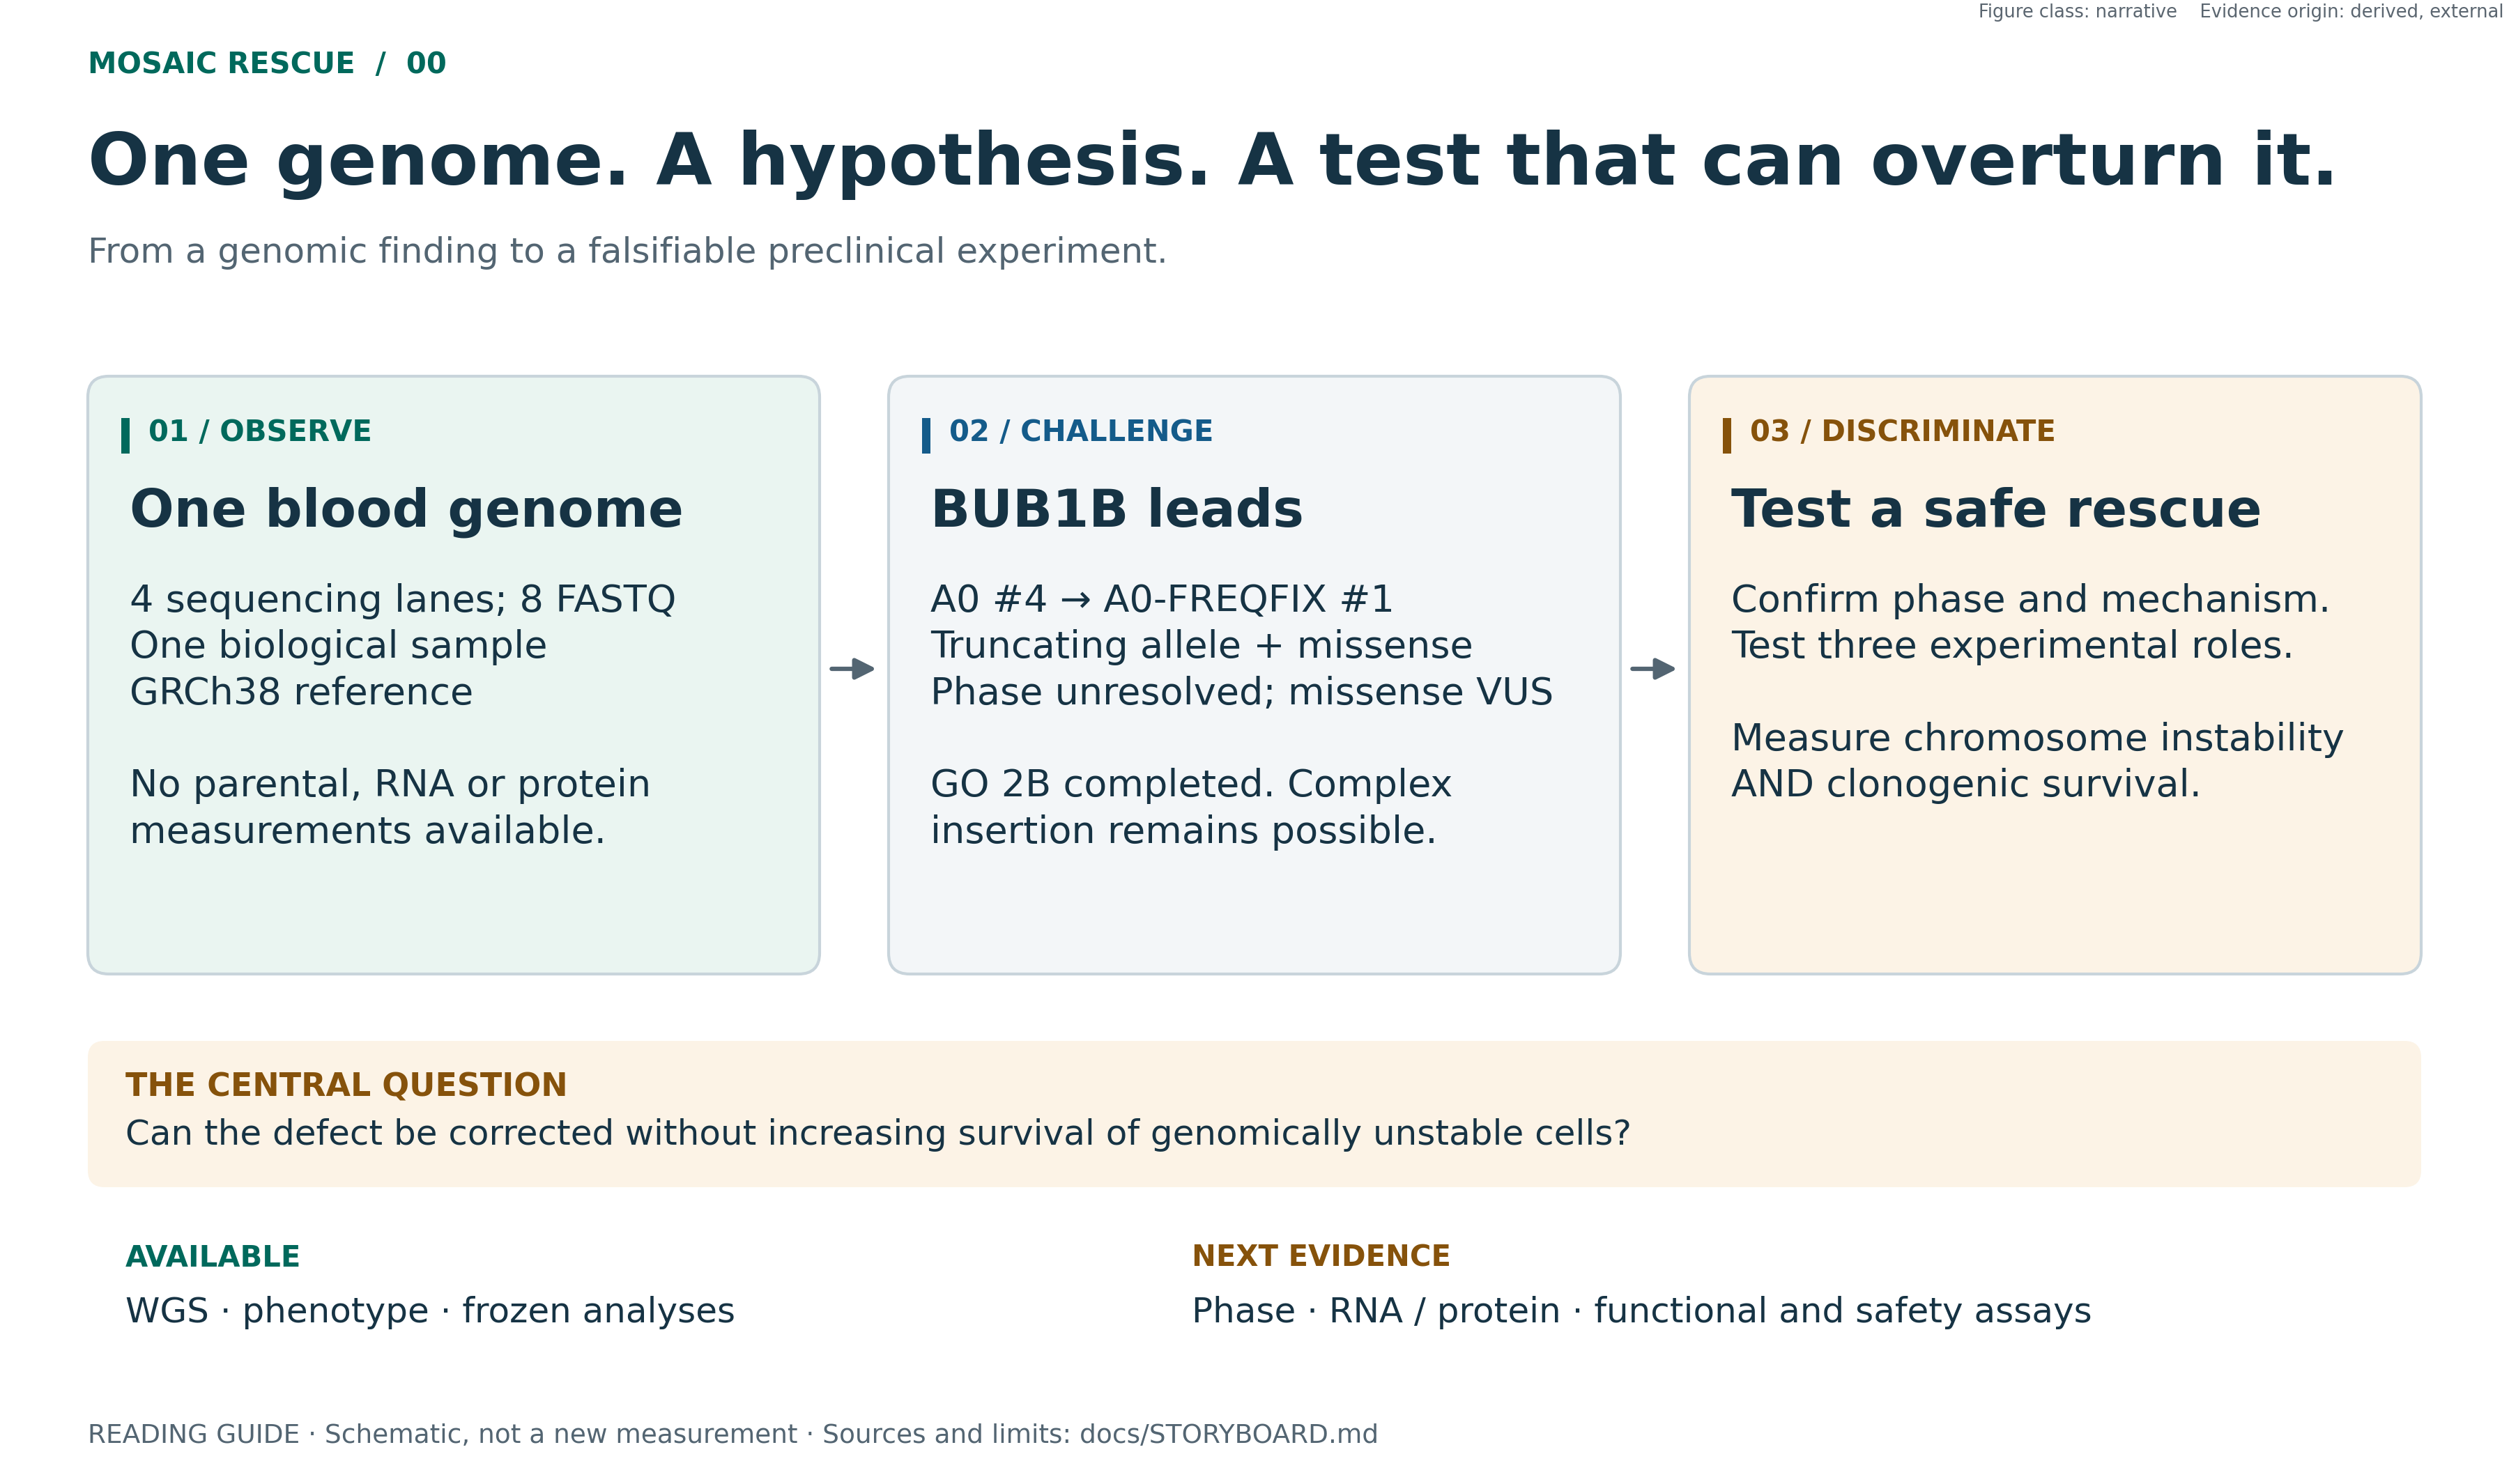

**`NARRATIVE`, DERIVED / EXTERNAL.** The frozen A0 ranking and its A0-FREQFIX revision are separate stages. Several tools agreeing on the same VCF is not biological replication. Reviewed figure, embedded without re-running the original analysis, [sources and limits](../docs/STORYBOARD.md), [figure QA](../PUBLICATION_FIGURE_QA.md)

In [1]:
import sys, os, io, json, pickle, collections
os.chdir("..")                       # the pipeline uses paths relative to the repo root
sys.path.insert(0, ".")
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
from src.nb import figlib as fl      # inline figures + provenance captions
print("Environment ready. Figures render inline, each with a provenance caption.")

Environment ready. Figures render inline, each with a provenance caption.


In [2]:
fl.labels("What it shows", "What it leaves out")

## Inputs and provenance

Hashes are checked. Annotation with VEP 116.1 offline (a 27 GB cache and hours of compute) is
an upstream step that **cannot be re-run here**: the notebook starts from its output and
checks its fingerprint.

In [3]:
import hashlib
from src.paths import patient_vcf

def h(p, n=64 << 20):
    return hashlib.sha256(io.open(p, "rb").read(n)).hexdigest()[:16]

VCF, ANN = patient_vcf(), "work/gw/highmod_ann.tsv"
print(f"  patient VCF        sha256[:16] = {h(VCF)}   ({os.path.getsize(VCF)/2**20:.0f} MB)")
print(f"  annotated TSV (VEP) sha256[:16] = {h(ANN)}   ({os.path.getsize(ANN)/2**20:.0f} MB)")
print(f"  python {sys.version.split()[0]} ,  no local path is printed")

  patient VCF        sha256[:16] = 645e4693e399b395   (301 MB)
  annotated TSV (VEP) sha256[:16] = 6bb5d13907efa9d5   (6 MB)
  python 3.12.10 ,  no local path is printed


## QC, exact VEP and VCF allele reconciliation

**The error this notebook uncovered.** `allele_key.py` existed, had 17 passing tests and was
documented as the fix for the join. **No module imported it**: `load()` still joined by
position, exactly what that module was written to fix.

VEP shifts the coordinate of indels relative to the VCF, so a positional join loses them. The
fix could not use `Uploaded_variation` (this TSV does not carry it); it reproduces VEP's
representation rules and joins on `(Location, Allele)`. No tolerances: proximity is not a join
key, and that shortcut had already been rejected because it can pair different neighbouring
indels.

In [4]:
os.environ["PYTEST_DISABLE_PLUGIN_AUTOLOAD"] = "1"
import subprocess
r = subprocess.run([sys.executable, "-m", "pytest", "tests/test_allele_key.py", "-q"],
                   capture_output=True, text=True)
print("  join tests:", r.stdout.strip().splitlines()[-1] if r.stdout.strip() else "no output")
assert r.returncode == 0, "the join tests fail: nothing below can be trusted"

  join tests: 17 passed in 0.02s


In [5]:
import gzip
from src.prioritization.genome_wide import load, rank, haplotypic_events

rows = load(ANN, VCF)                      # current join: (Location, Allele)
hm = [v for v in rows if v.impact in ("HIGH", "MODERATE")]

# The old join, rebuilt here only to measure the size of the bug: position alone.
want = {v.loc.split(":")[0] + ":" + v.loc.split(":")[1].split("-")[0] for v in rows}
seen_pos = set()
with gzip.open(VCF, "rt", errors="replace") as f:
    for line in f:
        if line[0] == "#":
            continue
        p = line.split("\t", 2)
        k = f"{p[0]}:{p[1]}"
        if k in want:
            seen_pos.add(k)

def is_indel(v):
    return "-" in v.loc.split(":")[1]

before_lost, after_lost = [], []
for v in hm:
    k = v.loc.split(":")[0] + ":" + v.loc.split(":")[1].split("-")[0]
    if k not in seen_pos:
        before_lost.append(v)
    if not v.gt:
        after_lost.append(v)

B = {"SNV": len({v.loc for v in before_lost if not is_indel(v)}),
     "indel": len({v.loc for v in before_lost if is_indel(v)}),
     "HIGH": len([v for v in before_lost if v.impact == "HIGH"])}
A = {"SNV": len({v.loc for v in after_lost if not is_indel(v)}),
     "indel": len({v.loc for v in after_lost if is_indel(v)}),
     "HIGH": len([v for v in after_lost if v.impact == "HIGH"])}
tot_before = len({v.loc for v in before_lost})
tot_after = len({v.loc for v in after_lost})
print(f"  HIGH/MODERATE positions without a genotype, positional join   : {tot_before}")
print(f"  HIGH/MODERATE positions without a genotype, (Location, Allele): {tot_after}")
print(f"  recovered: {tot_before - tot_after}  ({100*(tot_before-tot_after)/tot_before:.0f} %)")

  HIGH/MODERATE positions without a genotype, positional join   : 433
  HIGH/MODERATE positions without a genotype, (Location, Allele): 13
  recovered: 420  (97 %)


### QC figure, the size of the bug, and of the fix

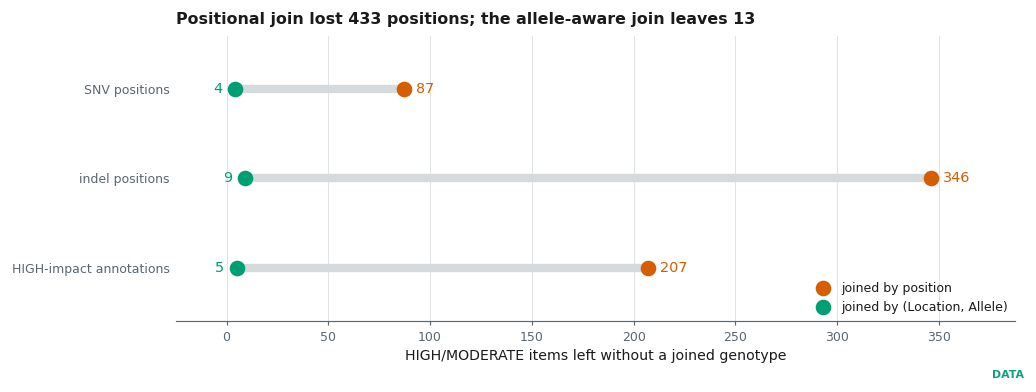

**QC figure: Allele reconciliation, before and after.** EXP-006; class `DATA` (scientific figure); evidence origin DERIVED.

*What it shows:* the positional join lost 433 HIGH/MODERATE positions, mostly indels, because VEP shifts their coordinate; 207 high-impact annotations were among them. Reproducing VEP's representation recovers 420.

*What it leaves out:* a perfect join: 13 positions remain unresolved, and a complex allele is declared unresolved rather than guessed.

<sub>Provenance: src/prioritization/allele_key.py, genome_wide.load().</sub>

In [6]:
fig, ax = plt.subplots(figsize=(8.6, 3.2))
cats = [("SNV positions", "SNV"), ("indel positions", "indel"), ("HIGH-impact annotations", "HIGH")]
for i, (lab, k) in enumerate(cats[::-1]):
    b, a = B[k], A[k]
    ax.plot([a, b], [i, i], color=fl.RULE, lw=5, solid_capstyle="round", zorder=1)
    ax.scatter([b], [i], s=70, color=fl.DEAD, zorder=3, label="joined by position" if i == 0 else None)
    ax.scatter([a], [i], s=70, color=fl.ALIVE, zorder=3, label="joined by (Location, Allele)" if i == 0 else None)
    ax.text(b + 6, i, f"{b}", va="center", fontsize=8.6, color=fl.DEAD)
    ax.text(a - 6, i, f"{a}", va="center", ha="right", fontsize=8.6, color=fl.ALIVE)
ax.set_yticks(range(len(cats))); ax.set_yticklabels([c[0] for c in cats[::-1]])
ax.set_xlim(-25, max(B.values()) * 1.12); ax.set_ylim(-0.6, len(cats) - 0.4)
ax.grid(axis="x"); ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.set_xlabel("HIGH/MODERATE items left without a joined genotype")
fl.title(ax, f"Positional join lost {tot_before} positions; the allele-aware join leaves {tot_after}")
ax.legend(loc="lower right", ncol=1)

fl.done(fig, "QC figure: Allele reconciliation, before and after", "EXP-006", "DERIVED",
        "DATA",
        f"the positional join lost {tot_before} HIGH/MODERATE positions, mostly indels, because "
        f"VEP shifts their coordinate; {B['HIGH']} high-impact annotations were among them. "
        f"Reproducing VEP's representation recovers {tot_before - tot_after}.",
        f"a perfect join: {tot_after} positions remain unresolved, and a complex allele is "
        "declared unresolved rather than guessed.",
        prov="src/prioritization/allele_key.py, genome_wide.load()")

## Method, genome-wide processing stages

Three decisions frozen in `config/ranking_v1.yaml` change the result: a two-level rule for
`FILTER`, normalisation to single alleles, and **haplotypic aggregation**: variants sharing
`PID` and `PGT` are proven to be in *cis* and collapse into one event.

In [7]:
pos_all = {v.loc for v in rows}
pos_hm = {v.loc for v in hm}
by_gene = collections.defaultdict(list)
for v in hm:
    by_gene[v.gene].append(v)

rare = [v for v in hm if v.is_rare]
qc_ok = [v for v in rare if v.passes_quality]
calls = rank(rows, male=True)

STAGES = [
    ("variants in the VCF",                5_012_204),
    ("annotated to a gene (VEP)",          4_943_948),
    ("HIGH or MODERATE positions",         len(pos_hm)),
    ("unique alleles with a genotype",     len({(v.loc, v.allele) for v in hm if v.gt})),
    ("rare (MAX_AF < 1e-3 or absent)",     len({(v.loc, v.allele) for v in rare})),
    ("+ quality and allele-balance QC",    len({(v.loc, v.allele) for v in qc_ok})),
    ("genes with an inheritance model",    len(calls)),
]
for n, v in STAGES:
    print(f"  {n:<36} {v:>10,}")

  variants in the VCF                   5,012,204
  annotated to a gene (VEP)             4,943,948
  HIGH or MODERATE positions               13,191
  unique alleles with a genotype           13,216
  rare (MAX_AF < 1e-3 or absent)              189
  + quality and allele-balance QC             159
  genes with an inheritance model             151


### Main figure 1. the processing stages, with the arithmetic visible

It is not called a *funnel*, for a reason: **one stage grows**. Going from **positions** with a
HIGH or MODERATE consequence to **unique alleles with a genotype**, the count rises, because a
multi-allelic position contributes more than one allele. Drawing it as a funnel implied a
reduction that does not happen there. The expanding stage is marked.

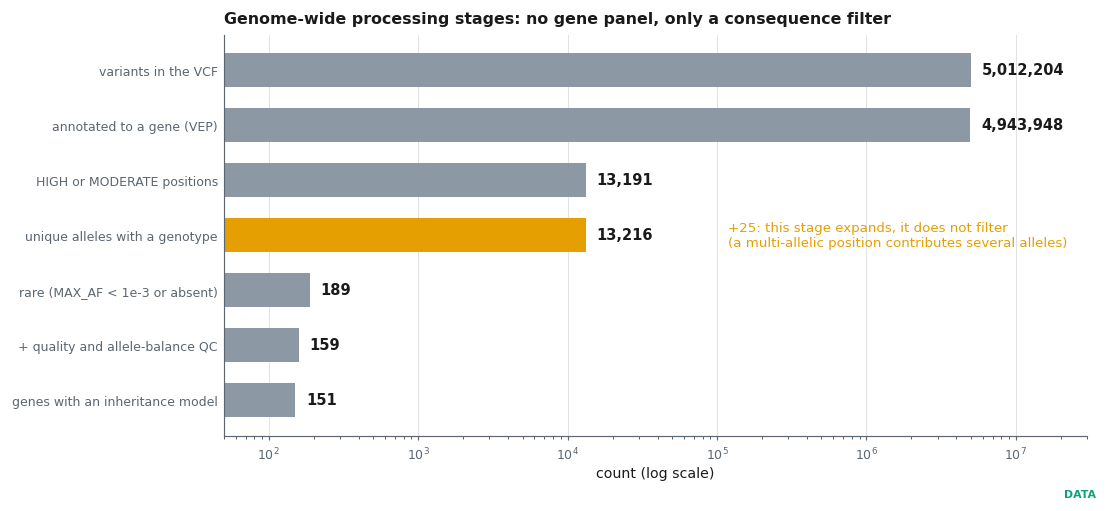

**Main figure 1: Genome-wide processing stages.** EXP-006; class `DATA` (scientific figure); evidence origin MEASURED and DERIVED.

*What it shows:* the real descent from 5.0 M variants to the genes that compete under an inheritance model. No stage is a panel: the only filter is functional consequence. The marked stage does not reduce, it expands, going from positions to unique alleles.

*What it leaves out:* anything the stages do not evaluate. Structural, regulatory and deep-intronic variants outside the consequence filter are not covered, and phase is not resolved.

<sub>Provenance: work/gw/highmod_ann.tsv + VCF, hashes above.</sub>

In [8]:
fig, ax = plt.subplots(figsize=(9.2, 4.2))
names = [s[0] for s in STAGES]
vals = [s[1] for s in STAGES]
y = np.arange(len(STAGES))[::-1]
cols = [fl.FLOW] * len(vals)
for i in range(1, len(vals)):
    if vals[i] > vals[i - 1]:
        cols[i] = fl.OPEN
ax.barh(y, vals, height=0.62, color=cols)
ax.set_xscale("log"); ax.set_xlim(50, 3e7)
for yi, v in zip(y, vals):
    ax.text(v * 1.18, yi, f"{v:,}", va="center", fontsize=8.8, fontweight="bold", color=fl.INK)
for i in range(1, len(vals)):
    if vals[i] > vals[i - 1]:
        ax.annotate(f"+{vals[i] - vals[i - 1]:,}: this stage expands, it does not filter\n"
                    "(a multi-allelic position contributes several alleles)",
                    xy=(vals[i], y[i]), xytext=(vals[i] * 9, y[i]),
                    fontsize=8, color=fl.OPEN, va="center")
ax.set_yticks(y); ax.set_yticklabels(names)
ax.grid(axis="x"); ax.tick_params(axis="y", length=0)
ax.set_xlabel("count (log scale)")
fl.title(ax, "Genome-wide processing stages: no gene panel, only a consequence filter")

fl.done(fig, "Main figure 1: Genome-wide processing stages", "EXP-006",
        "MEASURED+DERIVED", "DATA",
        "the real descent from 5.0 M variants to the genes that compete under an inheritance "
        "model. No stage is a panel: the only filter is functional consequence. The marked "
        "stage does not reduce, it expands, going from positions to unique alleles.",
        "anything the stages do not evaluate. Structural, regulatory and deep-intronic variants "
        "outside the consequence filter are not covered, and phase is not resolved.",
        prov="work/gw/highmod_ann.tsv + VCF, hashes above")

## Main figure 2. where the competition happens on the genome

The stages say **how many** genes compete. They do not say **where** or **with what score**.
This view shows every gene that received an inheritance model, placed on its chromosome, with
its **frozen** `A0` score on the y axis.

> **Sanitised by design.** The x axis is chromosome order in **1 Mb bins** derived from the
> gene's position, not the coordinate of any patient variant. Chromosome lengths are read from
> the VCF header, not typed in.

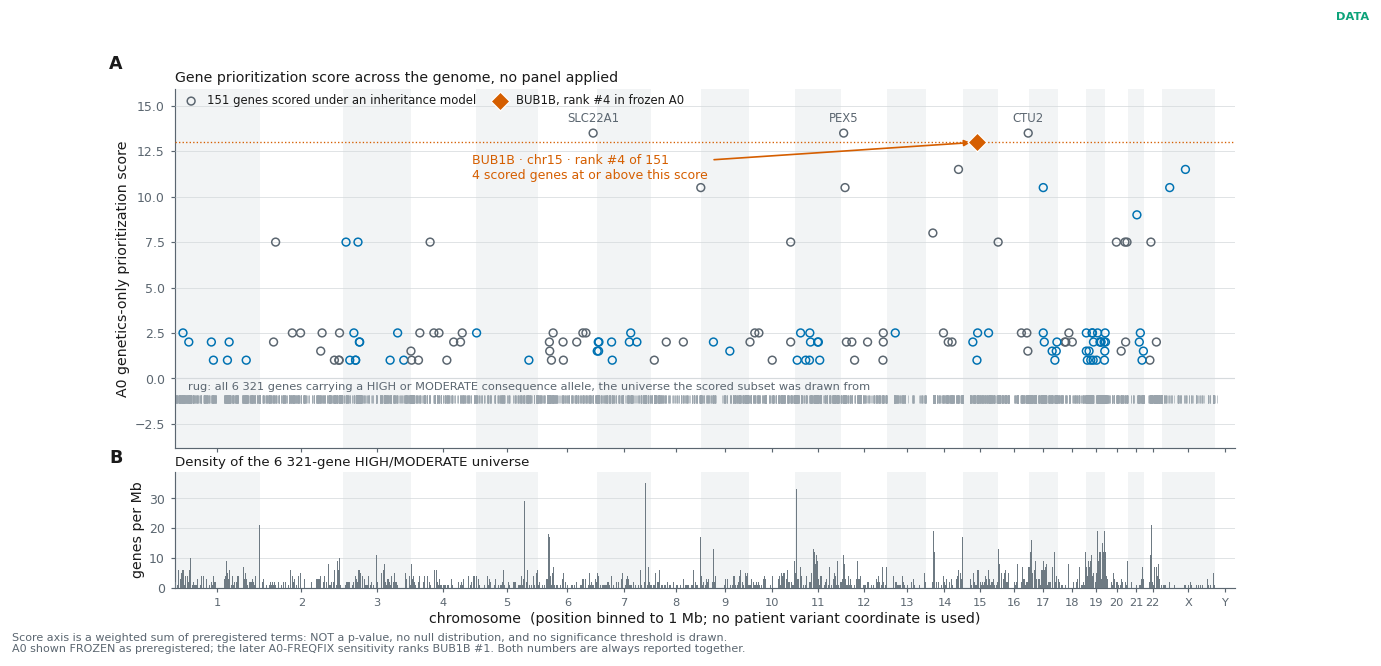

**Main figure 2: Genome-wide prioritisation.** EXP-006; class `DATA` (scientific figure); evidence origin MEASURED and DERIVED.

*What it shows:* the whole competition on the genome: the 6,321 genes carrying a HIGH/MODERATE variant form the universe (rug on the baseline and density in panel B), and the 151 that reached an inheritance model are plotted with their frozen A0 score. BUB1B is marked at its real frozen-A0 rank, #4, with 4 genes tied or above. It was not 151 genes that competed but 6,321.

*What it leaves out:* a probability or a p-value. The y axis is a sum of terms with weights we chose: it is not a statistic, has no null distribution, and so the figure refuses to draw a significance line. It does not cover structural or regulatory variants, and the x position is the gene's 1 Mb bin, not that of any variant.

<sub>Data: work/gw/mode_b_results_v4.pkl (frozen A0) + VCF contig lengths. Library: matplotlib. Provenance: figures/pub/fig01_prioritization_genomewide.svg + .png 300 dpi.</sub>

In [9]:
res = pickle.load(io.open("work/gw/mode_b_results_v4.pkl", "rb"))
from src.figures import fig01_manhattan as FM

M = FM.prepare(by_gene, res["A0_GENETICS"], FM.contig_lengths(VCF))
fig = FM.build(M)
_bub = next(s for s in M["scored"] if s["gene"] == "BUB1B")
_tie = sum(1 for s in M["scored"] if s["score"] >= _bub["score"])
fl.pub(fig, "Main figure 2: Genome-wide prioritisation", "EXP-006",
       "MEASURED+DERIVED", "DATA",
       f"the whole competition on the genome: the {M['n_universe']:,} genes carrying a "
       f"HIGH/MODERATE variant form the universe (rug on the baseline and density in panel B), "
       f"and the {M['n_scored']} that reached an inheritance model are plotted with their frozen "
       f"A0 score. BUB1B is marked at its real frozen-A0 rank, #{_bub['rank']}, with {_tie} genes "
       f"tied or above. It was not 151 genes that competed but {M['n_universe']:,}.",
       "a probability or a p-value. The y axis is a sum of terms with weights we chose: it is "
       "not a statistic, has no null distribution, and so the figure refuses to draw a "
       "significance line. It does not cover structural or regulatory variants, and the x "
       "position is the gene's 1 Mb bin, not that of any variant.",
       source="work/gw/mode_b_results_v4.pkl (frozen A0) + VCF contig lengths",
       lib="matplotlib", slug="fig01_prioritization_genomewide")

## Primary result, rank stability

What the preregistration requires is **not the winner** but the gene × analysis matrix. A gene
that wins under one configuration only is not a result.

In [10]:
ORDER = ["A0_GENETICS", "A1_GENETICS_CLINVAR", "B0_FULL_PROBAND",
         "B1_MINUS_RHABDOMYOSARCOMA", "B2_MINUS_RENAL", "B3_MINUS_GROWTH_PERINATAL",
         "B4_GENETICS_ONLY_CONTROL", "FH_ON"] + sorted(k for k in res if k.startswith("LOO_"))
LEAD = [r[0] for r in res["B0_FULL_PROBAND"][:6]]

RK = np.full((len(LEAD), len(ORDER)), np.nan)
for j, an in enumerate(ORDER):
    pos = {r[0]: i + 1 for i, r in enumerate(res[an])}
    for i, g in enumerate(LEAD):
        if g in pos:
            RK[i, j] = pos[g]
print(f"  {len(ORDER)} analyses, {len(LEAD)} leading genes")
print(f"  BUB1B is #1 in {int((RK[LEAD.index('BUB1B')] == 1).sum())} of {len(ORDER)}")

  15 analyses, 6 leading genes
  BUB1B is #1 in 14 of 15


### Main figure 3. rank-stability matrix

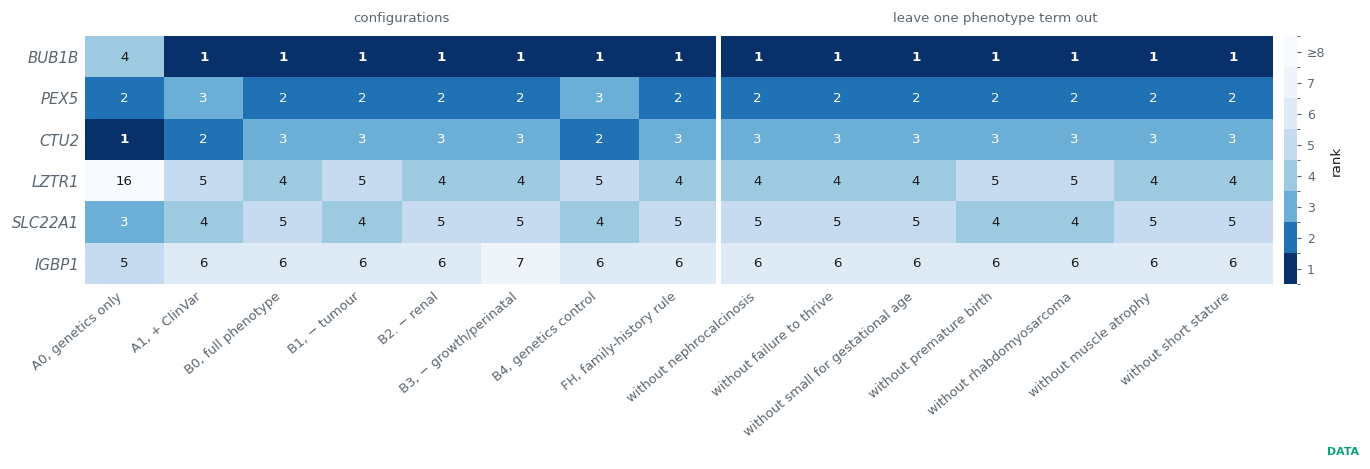

**Main figure 3: Rank stability, gene x analysis.** EXP-006; class `DATA` (scientific figure); evidence origin DERIVED.

*What it shows:* BUB1B is #1 in 14 of the 15 analyses. The exception is A0, the control without phenotype or ClinVar, where it is #4. The finding is not the winner of one formula: the result is stable when terms are removed, when ClinVar is removed and when weights change.

*What it leaves out:* independence. The 15 analyses share code, data and assumptions: they are not 15 independent checks.

<sub>Provenance: work/gw/mode_b_results_v4.pkl.</sub>

In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
HPO_NAME = {"HP_0002859": "rhabdomyosarcoma", "HP_0000121": "nephrocalcinosis",
            "HP_0004322": "short stature", "HP_0001508": "failure to thrive",
            "HP_0003202": "muscle atrophy", "HP_0001622": "premature birth",
            "HP_0001518": "small for gestational age"}
def an_label(a):
    if a.startswith("LOO_"):
        return "without " + HPO_NAME.get(a[4:], a[4:])
    return {"A0_GENETICS": "A0, genetics only", "A1_GENETICS_CLINVAR": "A1, + ClinVar",
            "B0_FULL_PROBAND": "B0, full phenotype", "B1_MINUS_RHABDOMYOSARCOMA": "B1, − tumour",
            "B2_MINUS_RENAL": "B2. − renal", "B3_MINUS_GROWTH_PERINATAL": "B3, − growth/perinatal",
            "B4_GENETICS_ONLY_CONTROL": "B4, genetics control", "FH_ON": "FH, family-history rule"}.get(a, a)

# Discrete, colour-blind-safe scale: rank 1 dark, rank ≥ 8 pale. Ranks above 8 are clipped
# for colour only; the printed number is always the true rank.
cmap = ListedColormap(["#08306B", "#2171B5", "#6BAED6", "#9ECAE1", "#C6DBEF", "#DEEBF7", "#EEF4FA", "#F7FBFF"])
norm = BoundaryNorm(np.arange(0.5, 9.5, 1), cmap.N)
fig, ax = plt.subplots(figsize=(11.4, 3.9))
im = ax.imshow(np.clip(RK, 1, 8), cmap=cmap, norm=norm, aspect="auto")
ax.set_yticks(range(len(LEAD))); ax.set_yticklabels(LEAD, fontsize=9, fontstyle="italic")
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([an_label(a) for a in ORDER], rotation=40, ha="right", fontsize=7.8)
for i in range(len(LEAD)):
    for j in range(len(ORDER)):
        if not np.isnan(RK[i, j]):
            v = int(RK[i, j])
            ax.text(j, i, str(v), ha="center", va="center", fontsize=8,
                    color="white" if v <= 3 else fl.INK, fontweight="bold" if v == 1 else "normal")
ax.axvline(7.5, color="white", lw=3)
ax.text(3.5, -0.85, "configurations", ha="center", fontsize=8, color=fl.SOFT)
ax.text(11.0, -0.85, "leave one phenotype term out", ha="center", fontsize=8, color=fl.SOFT)
ax.tick_params(length=0); [s.set_visible(False) for s in ax.spines.values()]
cb = plt.colorbar(im, ax=ax, fraction=0.018, pad=0.01, ticks=range(1, 9))
cb.ax.set_yticklabels([str(i) for i in range(1, 8)] + ["≥8"]); cb.set_label("rank", fontsize=8)
cb.outline.set_visible(False)

fl.done(fig, "Main figure 3: Rank stability, gene x analysis", "EXP-006", "DERIVED",
        "DATA",
        "BUB1B is #1 in 14 of the 15 analyses. The exception is A0, the control without "
        "phenotype or ClinVar, where it is #4. The finding is not the winner of one formula: "
        "the result is stable when terms are removed, when ClinVar is removed and when weights "
        "change.",
        "independence. The 15 analyses share code, data and assumptions: they are not 15 "
        "independent checks.",
        prov="work/gw/mode_b_results_v4.pkl")

### Main figure 4. frozen `A0` against `A0-FREQFIX`

This is the most important episode of the experiment, and **both numbers are shown together**.

When the allele join was wired in, `BUB1B` moved from #1 to **#4** in `A0`. Its score **did not
drop**: three homozygous deletions with no assignable `MAX_AF` rose above it. The audit
resolved them locally as **common polymorphisms** that VEP had failed to annotate.

**The formula was not touched.** `A0-FREQFIX` is a sensitivity analysis **run after seeing the
result**, applied to all 33 affected alleles, not just the three inconvenient ones.

In [12]:
# A0-FREQFIX: recomputed after repairing the frequency of every allele that lacked one
from src.prioritization.freqfix_sensitivity import recovered_frequencies

def a0_from(rws):
    out = []
    for c in rank(rws, male=True):
        s = c.score
        if any("pathogenic" in (x.clinsig or "").lower()
               and "conflicting" not in (x.clinsig or "").lower() for x in c.variants):
            s -= 5.0
        out.append((s, c.gene))
    return sorted(out, key=lambda t: (-t[0], t[1]))

a0_frozen = a0_from(load(ANN, VCF))

freq = recovered_frequencies()
rows_fx = load(ANN, VCF)
patched = 0
for v in rows_fx:
    if v.max_af is not None:
        continue
    base = int(v.loc.split(":")[1].split("-")[0])
    for d in (0, -1, -2):
        if (v.chrom, base + d) in freq:
            v.max_af = freq[(v.chrom, base + d)]; patched += 1; break
a0_fix = a0_from(rows_fx)

rk_f = next(i for i, (_, g) in enumerate(a0_frozen, 1) if g == "BUB1B")
rk_x = next(i for i, (_, g) in enumerate(a0_fix, 1) if g == "BUB1B")
print(f"  frequencies repaired: {len(freq)} sites, {patched} rows")
print(f"  frozen A0   : BUB1B rank {rk_f}")
print(f"  A0-FREQFIX  : BUB1B rank {rk_x}")

  frequencies repaired: 22 sites, 37 rows
  frozen A0   : BUB1B rank 4
  A0-FREQFIX  : BUB1B rank 1


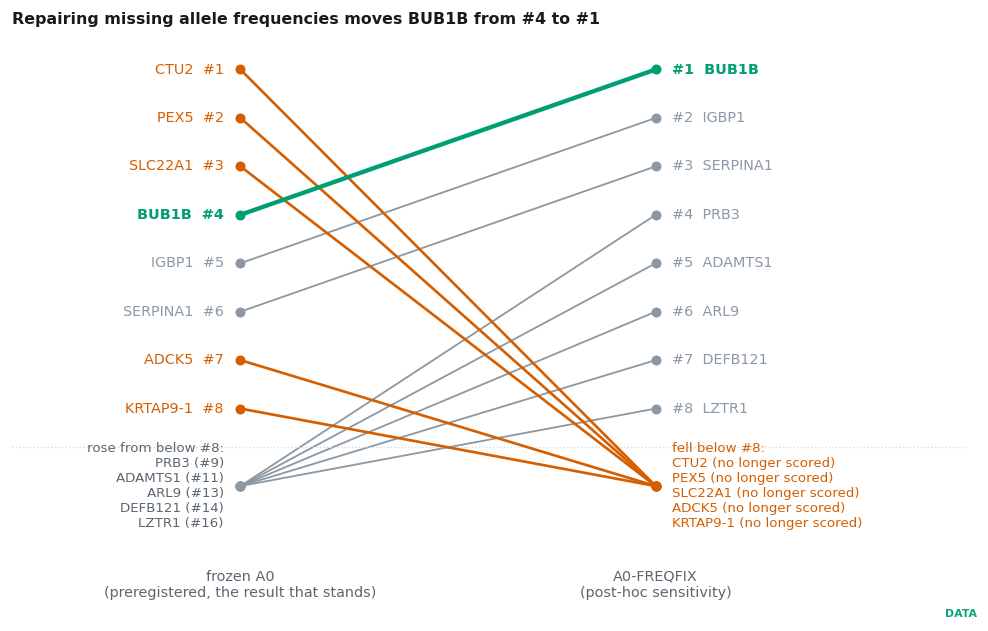

**Main figure 4: Frozen A0 against A0-FREQFIX.** EXP-006, EXP-021b; class `DATA` (scientific figure); evidence origin DERIVED.

*What it shows:* in the preregistered A0, BUB1B is #4, behind three homozygous deletions with no assignable frequency. Repairing the annotation defect in all affected alleles returns it to #1: every gene whose rank rested on an allele without a frequency (vermilion) is no longer scored once the allele is recognised as common. BUB1B's own score is unchanged: the others moved, not BUB1B.

*What it leaves out:* that A0-FREQFIX replaces A0. It is a sensitivity analysis run after seeing the result, and it repairs frequencies with Exomiser's local database, so it is not independent of Exomiser.

<sub>Provenance: frozen ranking + work/exomiser/runs/FREQFIX.</sub>

In [13]:
TOP = 8
rf = {g: i for i, (_, g) in enumerate(a0_frozen, 1)}
rx = {g: i for i, (_, g) in enumerate(a0_fix, 1)}
genes = list(dict.fromkeys([g for _, g in a0_frozen[:TOP]] + [g for _, g in a0_fix[:TOP]]))
OUTR = TOP + 1.6                                   # row used for "fell below the top 8"
def ypos(r):
    return r if r <= TOP else OUTR

fig, ax = plt.subplots(figsize=(8.2, 5.2))
dropped = [g for g in genes if rx.get(g, 10**6) > TOP]
for g in genes:
    a, b = ypos(rf.get(g, 10**6)), ypos(rx.get(g, 10**6))
    if g == "BUB1B":
        col, lw, z = fl.ALIVE, 2.6, 4
    elif g in dropped:
        col, lw, z = fl.DEAD, 1.6, 3
    else:
        col, lw, z = fl.FLOW, 1.1, 2
    ax.plot([0, 1], [a, b], color=col, lw=lw, zorder=z, marker="o", ms=5)
    if a <= TOP:
        ax.text(-0.04, a, f"{g}  #{rf[g]}", ha="right", va="center", fontsize=8.6, color=col,
                fontweight="bold" if g == "BUB1B" else "normal")
    if b <= TOP:
        ax.text(1.04, b, f"#{rx[g]}  {g}", ha="left", va="center", fontsize=8.6, color=col,
                fontweight="bold" if g == "BUB1B" else "normal")
def _r(d, g):
    return f"#{d[g]}" if g in d else "no longer scored"
ax.text(1.04, OUTR, f"fell below #{TOP}:\n" + "\n".join(f"{g} ({_r(rx, g)})" for g in dropped),
        ha="left", va="center", fontsize=8, color=fl.DEAD)
entered = [g for g in genes if rf.get(g, 10**6) > TOP]
if entered:
    ax.text(-0.04, OUTR, f"rose from below #{TOP}:\n" + "\n".join(f"{g} ({_r(rf, g)})" for g in entered),
            ha="right", va="center", fontsize=8, color=fl.SOFT)
ax.axhline(TOP + 0.8, color=fl.RULE, lw=0.8, ls=":")
ax.set_xlim(-0.55, 1.75); ax.set_ylim(OUTR + 1.6, 0.3)
ax.set_xticks([0, 1]); ax.set_xticklabels(["frozen A0\n(preregistered, the result that stands)",
                                           "A0-FREQFIX\n(post-hoc sensitivity)"], fontsize=8.6)
ax.set_yticks([]); ax.grid(False)
for s in ("left", "bottom"):
    ax.spines[s].set_visible(False)
ax.tick_params(axis="x", length=0)
fl.title(ax, "Repairing missing allele frequencies moves BUB1B from #4 to #1")

fl.done(fig, "Main figure 4: Frozen A0 against A0-FREQFIX", "EXP-006, EXP-021b",
        "DERIVED", "DATA",
        f"in the preregistered A0, BUB1B is #{rk_f}, behind three homozygous deletions with no "
        f"assignable frequency. Repairing the annotation defect in all affected alleles "
        f"returns it to #{rk_x}: every gene whose rank rested on an allele without a frequency "
        f"(vermilion) is no longer scored once the allele is recognised as common. BUB1B's own "
        "score is unchanged: the others moved, not BUB1B.",
        "that A0-FREQFIX replaces A0. It is a sensitivity analysis run after seeing the result, "
        "and it repairs frequencies with Exomiser's local database, so it is not independent "
        "of Exomiser.",
        prov="frozen ranking + work/exomiser/runs/FREQFIX")

## External check, our engine against Exomiser

Exomiser started from the **original VCF** and the **same 7 HPO terms**, with its own knowledge
base. It received none of our candidates, scores or panels.

> **This is methodological convergence on the same VCF.** It is not independent biological
> evidence: both engines read the same genome and the same calling errors. Both flag `SERPINA1`,
> which shows that a shared artefact can move both.

In [14]:
from src.baseline.compare_baseline import read_exomiser
ext, path, nrows = read_exomiser("BASELINE-PRIMARY")
ext_rank = {g: r for r, g, _, _ in ext}
our_rank = {r[0]: i + 1 for i, r in enumerate(res["B0_FULL_PROBAND"])}

shared = [g for g in ext_rank if g in our_rank and (ext_rank[g] <= 25 or our_rank[g] <= 25)]
print(f"  Exomiser: {len(ext)} unique genes ({nrows} gene x inheritance rows)")
print(f"  BUB1B: our rank {our_rank.get('BUB1B')}, Exomiser rank {ext_rank.get('BUB1B')}")
print(f"  genes in the top 25 of either engine: {len(shared)}")

  Exomiser: 398 unique genes (470 gene x inheritance rows)
  BUB1B: our rank 1, Exomiser rank 2
  genes in the top 25 of either engine: 19


### Main figure 5. rank against rank

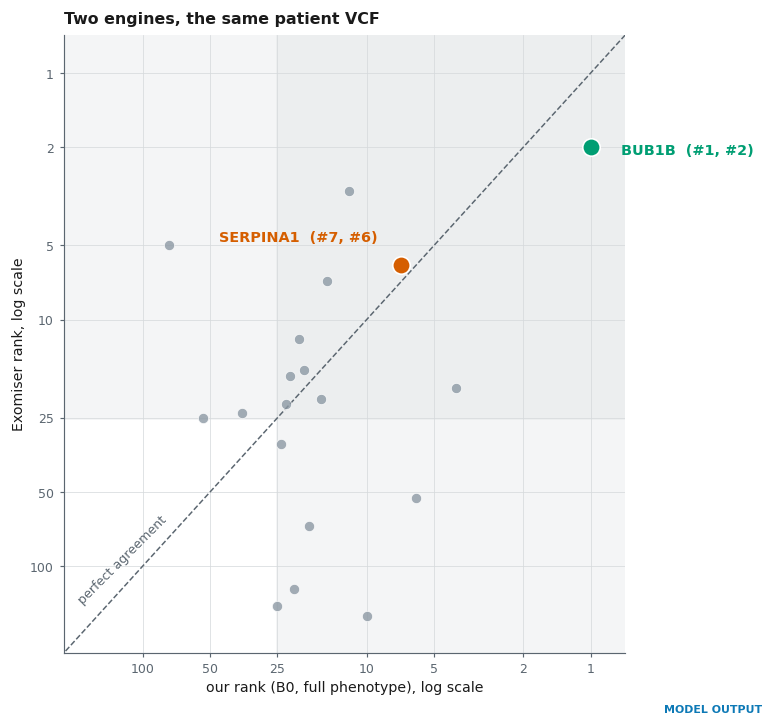

**Main figure 5: Our ranking against Exomiser.** EXP-006b; class `MODEL_OUTPUT` (scientific figure); evidence origin EXTERNAL and DERIVED.

*What it shows:* each point is a gene in the top 25 of either engine (shaded bands); the dashed line is perfect agreement. They agree strongly on BUB1B (#1 and #2) and weakly on the rest: the top-20 overlap is 6 of 20.

*What it leaves out:* two independent biological observations. They share the VCF, and a shared artefact fools both: SERPINA1 ranks high in both because of the same local quirk of the data.

<sub>Provenance: work/exomiser/runs/BASELINE-PRIMARY.</sub>

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 6.0))
xs = np.array([our_rank[g] for g in shared]); ys = np.array([ext_rank[g] for g in shared])
ax.axvspan(0.7, 25.5, color=fl.RULE, alpha=0.25, lw=0)
ax.axhspan(0.7, 25.5, color=fl.RULE, alpha=0.25, lw=0)
ax.scatter(xs, ys, s=38, color=fl.FLOW, alpha=0.8, edgecolor="white", lw=0.5, zorder=2)
lim = max(xs.max(), ys.max()) * 1.4
ax.plot([0.7, lim], [0.7, lim], color=fl.SOFT, ls="--", lw=0.9, zorder=1)
ax.text(lim * 0.55, lim * 0.42, "perfect agreement", rotation=45, fontsize=7.6, color=fl.SOFT,
        ha="center", va="center")
# Only the two points the text interprets are labelled, on opposite sides of the diagonal.
for g, c, off, ha in (("BUB1B", fl.ALIVE, (18, -4), "left"),
                      ("SERPINA1", fl.DEAD, (-14, 14), "right")):
    if g in shared:
        ax.scatter([our_rank[g]], [ext_rank[g]], s=110, color=c, zorder=3, edgecolor="white")
        ax.annotate(f"{g}  (#{our_rank[g]}, #{ext_rank[g]})", (our_rank[g], ext_rank[g]),
                    fontsize=8.6, color=c, xytext=off, textcoords="offset points", ha=ha,
                    fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lim, 0.7); ax.set_ylim(lim, 0.7)
ticks = [1, 2, 5, 10, 25, 50, 100]
ax.set_xticks([t for t in ticks if t < lim]); ax.set_xticklabels([str(t) for t in ticks if t < lim])
ax.set_yticks([t for t in ticks if t < lim]); ax.set_yticklabels([str(t) for t in ticks if t < lim])
ax.minorticks_off(); ax.grid(True, which="major")
ax.set_xlabel("our rank (B0, full phenotype), log scale")
ax.set_ylabel("Exomiser rank, log scale")
fl.title(ax, "Two engines, the same patient VCF")

fl.done(fig, "Main figure 5: Our ranking against Exomiser", "EXP-006b",
        "EXTERNAL+DERIVED", "MODEL_OUTPUT",
        "each point is a gene in the top 25 of either engine (shaded bands); the dashed line "
        "is perfect agreement. They agree strongly on BUB1B (#1 and #2) and weakly on the rest: "
        "the top-20 overlap is 6 of 20.",
        "two independent biological observations. They share the VCF, and a shared artefact "
        "fools both: SERPINA1 ranks high in both because of the same local quirk of the data.",
        prov="work/exomiser/runs/BASELINE-PRIMARY")

## Robustness, which phenotype terms actually carry the result

*Leave-one-out*: one term is removed and the change in the leading gene's phenotypic support is
measured.

In [16]:
G = res["B0_FULL_PROBAND"][0][0]
base = next(r for r in res["B0_FULL_PROBAND"] if r[0] == G)[5]
loo = []
for k in sorted(k for k in res if k.startswith("LOO_")):
    v = next((r for r in res[k] if r[0] == G), None)
    if v:
        loo.append((HPO_NAME.get(k.replace("LOO_", ""), k), base - v[5]))
loo.sort(key=lambda t: t[1])
print(f"  gene: {G}, full phenotypic support = {base:.3f}")
for n, d in loo:
    print(f"    {n:<28}{d:+.3f}")

  gene: BUB1B, full phenotypic support = 2.053
    muscle atrophy              -0.250
    failure to thrive           -0.152
    short stature               -0.131
    nephrocalcinosis            -0.095
    premature birth             -0.083
    small for gestational age   +0.133
    rhabdomyosarcoma            +0.579


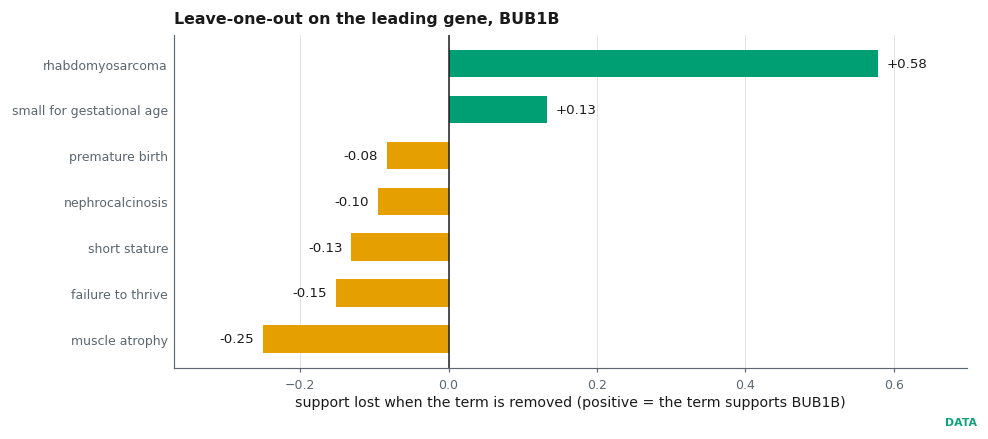

**Robustness figure: Contribution of each phenotype term.** EXP-006; class `DATA` (scientific figure); evidence origin DERIVED.

*What it shows:* only rhabdomyosarcoma carries the match strongly. The other terms contribute little or negatively in the current HPO corpus.

*What it leaves out:* that a negative value means MVA does not explain that trait. Under Best Match Average, removing a term that scores below the mean raises the average. EXP-019 settled the question by checking membership in the annotated disease model, not with these contributions: failure to thrive is covered in 93.5 % of the literature even though HPO does not annotate it.

<sub>Provenance: work/gw/mode_b_results_v4.pkl, docs/PHENOTYPE_RESIDUAL_AUDIT.md.</sub>

In [17]:
fig, ax = plt.subplots(figsize=(8.2, 3.6))
names = [n for n, _ in loo]; vals = [d for _, d in loo]
cols = [fl.ALIVE if v > 0.05 else (fl.FLOW if v > -0.05 else fl.OPEN) for v in vals]
ax.barh(range(len(names)), vals, color=cols, height=0.6)
ax.axvline(0, color=fl.INK, lw=0.9)
for i, v in enumerate(vals):
    ax.text(v + (0.012 if v >= 0 else -0.012), i, f"{v:+.2f}", va="center",
            ha="left" if v >= 0 else "right", fontsize=8, color=fl.INK)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
ax.set_xlim(min(vals) - 0.12, max(vals) + 0.12); ax.grid(axis="x")
ax.tick_params(axis="y", length=0)
ax.set_xlabel("support lost when the term is removed (positive = the term supports BUB1B)")
fl.title(ax, f"Leave-one-out on the leading gene, {G}")

fl.done(fig, "Robustness figure: Contribution of each phenotype term", "EXP-006", "DERIVED", "DATA",
        "only rhabdomyosarcoma carries the match strongly. The other terms contribute little or "
        "negatively in the current HPO corpus.",
        "that a negative value means MVA does not explain that trait. Under Best Match Average, "
        "removing a term that scores below the mean raises the average. EXP-019 settled the "
        "question by checking membership in the annotated disease model, not with these "
        "contributions: failure to thrive is covered in 93.5 % of the literature even though HPO "
        "does not annotate it.",
        prov="work/gw/mode_b_results_v4.pkl, docs/PHENOTYPE_RESIDUAL_AUDIT.md")

## Alternative explanations and contradicting evidence

| Alternative | Status |
|---|---|
| `BUB1B` rises because of the phenotype we supplied | **Rejected**: in `A0`, without phenotype or ClinVar, it is still the highest-scoring credible candidate |
| `BUB1B` rises because of ClinVar | **Rejected**: `A0` removes the ClinVar points |
| The three genes above it in `A0` are real competitors | **Rejected**: common polymorphisms, with up to 313 150 homozygotes in gnomAD |
| `FANCD2`, from the external top 10 | **Negative**: alleles at ~47 % and all three heterozygous |
| A competitor that neither engine sees | **Open**: both share the VCF and neither sees structural variants |

## Decision

| | |
|---|---|
| **EXP-006 status** | **Survives** |
| Prediction #4 | **Correct**: it asked for the top 20; `BUB1B` is #1 in 14 of 15 analyses |
| Frozen `A0` | **#4**, and reported as such |
| `A0-FREQFIX` | **#1**, labelled as a post-hoc sensitivity analysis not independent of Exomiser |

### What it does not establish

It does not resolve phase, it does not assess *de novo* status without parents, on its own it
does not cover structural variants (addressed later in GO 2B), it does not cover regulatory or
deep-intronic variants, **it classifies nothing as pathogenic**.

### Falsifier

A gene with a clean evidence profile (rare variants, assignable frequency, a compatible
inheritance model) outranking `BUB1B` in the frozen `A0`. It happened, it was investigated, and
the three candidates turned out to be common polymorphisms.

### Next

`02_BUB1B_ALLELE_CURATION`: what each allele supports on its own, and why phase decides.

In [18]:
# Print only the verdict, never the body of the report.
#
# Dumping r.stdout here was a leak channel created by the control itself: the scanner quotes
# the text it finds, so printing it inside a versioned notebook copied the finding into a
# versioned file. The scanner found its own quotations inside this notebook.
r = subprocess.run([sys.executable, "src/sanitize_scan.py"], capture_output=True, text=True,
                   env={**os.environ, "PYTHONIOENCODING": "utf-8"})
out = r.stdout
n = 0
for line in out.splitlines():
    t = line.strip()
    if t.endswith("COINCIDENCIAS:"):
        n = int(t.split()[0])
print(f"  sanitisation scan of versioned files: "
      f"{'CLEAN' if 'LIMPIO' in out else str(n) + ' match(es)'}")
print("  the detail is deliberately not printed here: run `python src/sanitize_scan.py`")

  sanitisation scan of versioned files: CLEAN
  the detail is deliberately not printed here: run `python src/sanitize_scan.py`
